# EDA: IEEE-CIS Fraud Detection

Goal: understand fraud rate, transaction amount distribution, missing data
patterns, and whether fraud rate drifts over time (which justifies a
time-based split over a random one).

In [1]:
import sys
sys.path.append("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.data.load import load_labeled_data
from src.data.split import time_based_split

plt.rcParams["figure.figsize"] = (9, 4)

df = load_labeled_data()
df.shape

(590540, 434)

## 1. Fraud rate (class imbalance)

In [2]:
fraud_rate = df["isFraud"].mean()
print(f"Overall fraud rate: {fraud_rate:.4%}")
print(f"Imbalance ratio (legit:fraud): {(1 - fraud_rate) / fraud_rate:.1f} : 1")
df["isFraud"].value_counts().rename({0: "legit", 1: "fraud"})

Overall fraud rate: 3.4990%
Imbalance ratio (legit:fraud): 27.6 : 1


isFraud
legit    569877
fraud     20663
Name: count, dtype: int64

Fraud is ~3.5% of transactions â€” a ~27:1 imbalance. This rules out plain
accuracy as a metric and motivates PR-AUC + explicit imbalance handling
(class weights / SMOTE) in the modeling step.

## 2. Transaction amount distribution

count    590540.000000
mean        135.027176
std         239.162522
min           0.251000
25%          43.321000
50%          68.769000
75%         125.000000
max       31937.391000
Name: TransactionAmt, dtype: float64


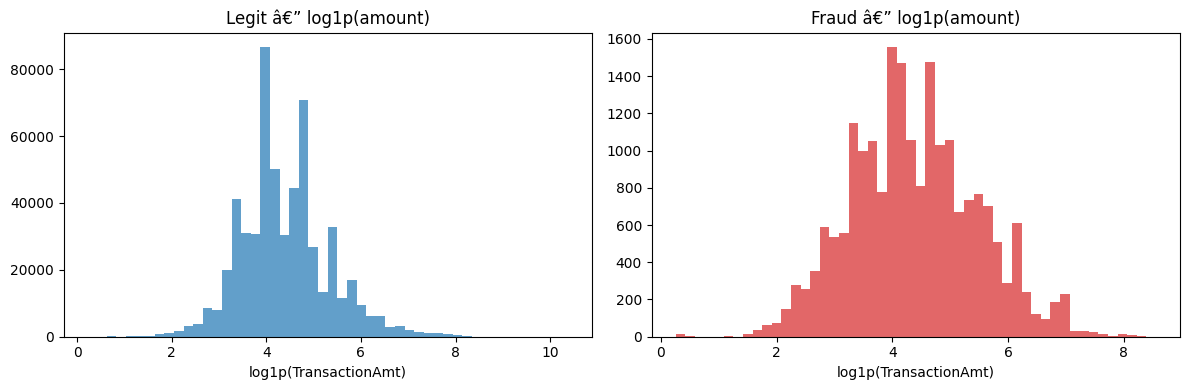

In [3]:
print(df["TransactionAmt"].describe())

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, fraud_flag, label, color in [
    (axes[0], 0, "Legit", "tab:blue"),
    (axes[1], 1, "Fraud", "tab:red"),
]:
    data = df.loc[df["isFraud"] == fraud_flag, "TransactionAmt"]
    ax.hist(np.log1p(data), bins=50, color=color, alpha=0.7)
    ax.set_title(f"{label} â€” log1p(amount)")
    ax.set_xlabel("log1p(TransactionAmt)")
plt.tight_layout()
plt.savefig("../reports/amount_distribution.png", dpi=120)
plt.show()

Fraudulent transactions skew toward a different amount profile than legit
ones (visible in the log-scaled histograms above) â€” this is a strong
candidate predictive feature on its own, which is why `log_amount` is
included in feature engineering (Step 3).

## 3. Missing values

In [4]:
missing = df.isna().mean().sort_values(ascending=False)
missing_summary = missing[missing > 0]
print(f"{len(missing_summary)} / {df.shape[1]} columns have missing values")
missing_summary.head(20)

414 / 434 columns have missing values


id_24    0.991962
id_25    0.991310
id_07    0.991271
id_08    0.991271
id_21    0.991264
id_26    0.991257
id_27    0.991247
id_23    0.991247
id_22    0.991247
dist2    0.936284
D7       0.934099
id_18    0.923607
D13      0.895093
D14      0.894695
D12      0.890410
id_03    0.887689
id_04    0.887689
D6       0.876068
id_33    0.875895
id_10    0.873123
dtype: float64

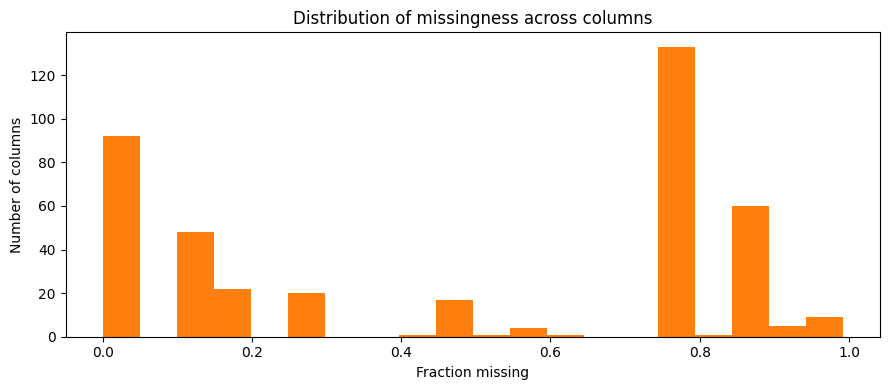

Columns >90% missing: 12
Columns >50% missing: 214


In [5]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(missing_summary.values, bins=20, color="tab:orange")
ax.set_xlabel("Fraction missing")
ax.set_ylabel("Number of columns")
ax.set_title("Distribution of missingness across columns")
plt.tight_layout()
plt.savefig("../reports/missing_values.png", dpi=120)
plt.show()

print("Columns >90% missing:", (missing_summary > 0.9).sum())
print("Columns >50% missing:", (missing_summary > 0.5).sum())

Most missingness is concentrated in the `id_*` identity columns (not every
transaction has device/browser identity data joined) and a subset of the
anonymized `V*` columns, which tend to be missing in blocks â€” consistent with
different `V` columns coming from different underlying feature groups.
Columns above 90% missing are dropped in feature engineering (Step 3).

## 4. Fraud rate trend over time

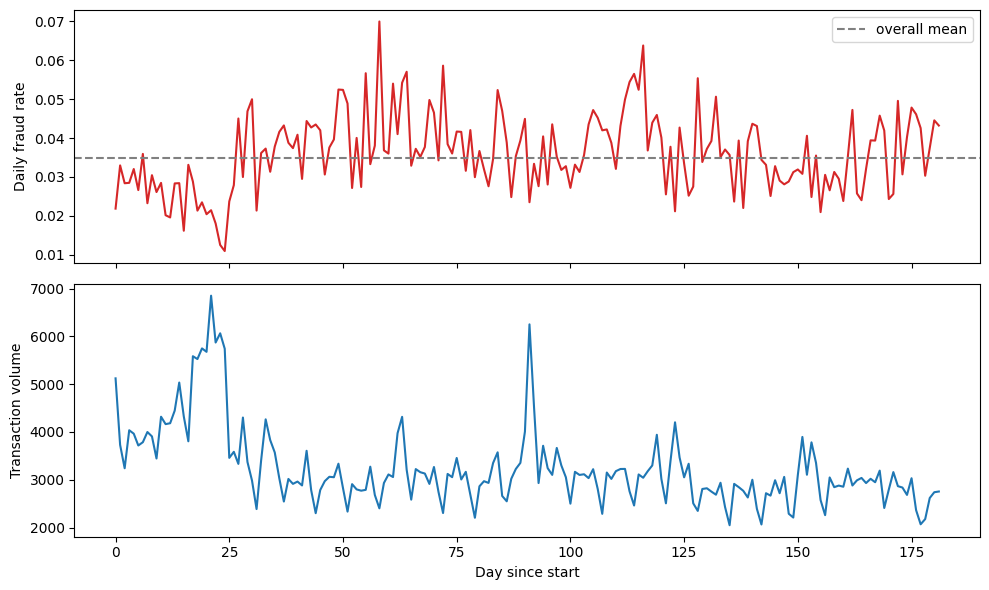

In [6]:
df_sorted = df.sort_values("TransactionDT").copy()
df_sorted["day"] = (df_sorted["TransactionDT"] - df_sorted["TransactionDT"].min()) // 86400

daily_fraud_rate = df_sorted.groupby("day")["isFraud"].mean()
daily_volume = df_sorted.groupby("day")["isFraud"].size()

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
ax1.plot(daily_fraud_rate.index, daily_fraud_rate.values, color="tab:red")
ax1.axhline(fraud_rate, color="gray", linestyle="--", label="overall mean")
ax1.set_ylabel("Daily fraud rate")
ax1.legend()

ax2.plot(daily_volume.index, daily_volume.values, color="tab:blue")
ax2.set_ylabel("Transaction volume")
ax2.set_xlabel("Day since start")
plt.tight_layout()
plt.savefig("../reports/fraud_rate_over_time.png", dpi=120)
plt.show()

Fraud rate visibly fluctuates week to week rather than staying flat â€” this
is exactly why a **random** split would be misleading: it would let the
model implicitly see future fraud patterns during training. A time-based
split (train = earliest 70%, val = next 15%, test = most recent 15%)
mirrors real deployment, where the model only ever sees the past.

## 5. Time-based split sanity check

In [7]:
train, val, test = time_based_split(df)

for name, split in [("train", train), ("val", val), ("test", test)]:
    days = (split["TransactionDT"].max() - split["TransactionDT"].min()) / 86400
    print(
        f"{name:5s}: {len(split):>7,} rows | "
        f"fraud rate {split['isFraud'].mean():.4%} | "
        f"span {days:.1f} days"
    )

assert len(set(train.TransactionID) & set(val.TransactionID)) == 0
assert len(set(val.TransactionID) & set(test.TransactionID)) == 0
print("\nNo TransactionID overlap between splits: confirmed.")

train: 413,378 rows | fraud rate 3.5169% | span 119.8 days
val  :  88,581 rows | fraud rate 3.4341% | span 31.4 days
test :  88,581 rows | fraud rate 3.4804% | span 30.8 days

No TransactionID overlap between splits: confirmed.


## Summary

- **Fraud rate**: 3.50% overall â€” severe class imbalance, use PR-AUC not accuracy.
- **Amount**: fraud has a distinct amount distribution vs legit â€” useful signal.
- **Missing data**: concentrated in `id_*` and blocks of `V*` columns; drop >90% missing columns.
- **Time**: fraud rate drifts over time, confirming the need for a time-based
  (not random) split. Splits are consistent in fraud rate (~3.4-3.5%) and have
  zero `TransactionID` overlap.